# 5. Шинжилгээ ба дүгнэлт (Хэсэг 5)

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
P, R, F = ROOT / "data" / "processed", ROOT / "reports", ROOT / "figures"
def show(name):
    display(Image(filename=str(F / f"{name}.png"), width=760))

In [2]:
hyp = pd.read_csv(R / "hypotheses.csv"); hyp

,hid,statement,estimate,ci_lo,ci_hi,null_value,p_value,n,method
0,H1,Import тоглогчид дотоодынхоос илүү оноо авдаг ...,10.650000,9.400000,13.100000,0.0,2.269301e-24,273,"Mann-Whitney U (нэг талт), rank-biserial r = 0..."
1,H2,Гэрийн баг 50%-аас илүү ялдаг (талбайн давуу тал),0.465116,0.399642,0.531815,0.5,3.397006e-01,215,Binomial тест; CI: Wilson
2,H3,Four Factors дотроос eFG% нь ялалтыг хамгийн х...,3.832923,3.505511,4.227078,0.0,NaN,0,Стандартчилсан logistic regression; |коэф|-ийн...
3,H4,Өндөр тоглогчид илүү их самбар авдаг (Pearson r),0.628142,0.548059,0.696813,0.0,1.003971e-29,258,Pearson r; Spearman ρ = 0.51; CI: Fisher z
4,H5,Авсан/алдсан оноо ялалтын хувийг сайн тайлбарл...,0.886159,0.792264,0.942157,0.0,NaN,33,"Pythagorean expectation, тааруулсан экспонент ..."


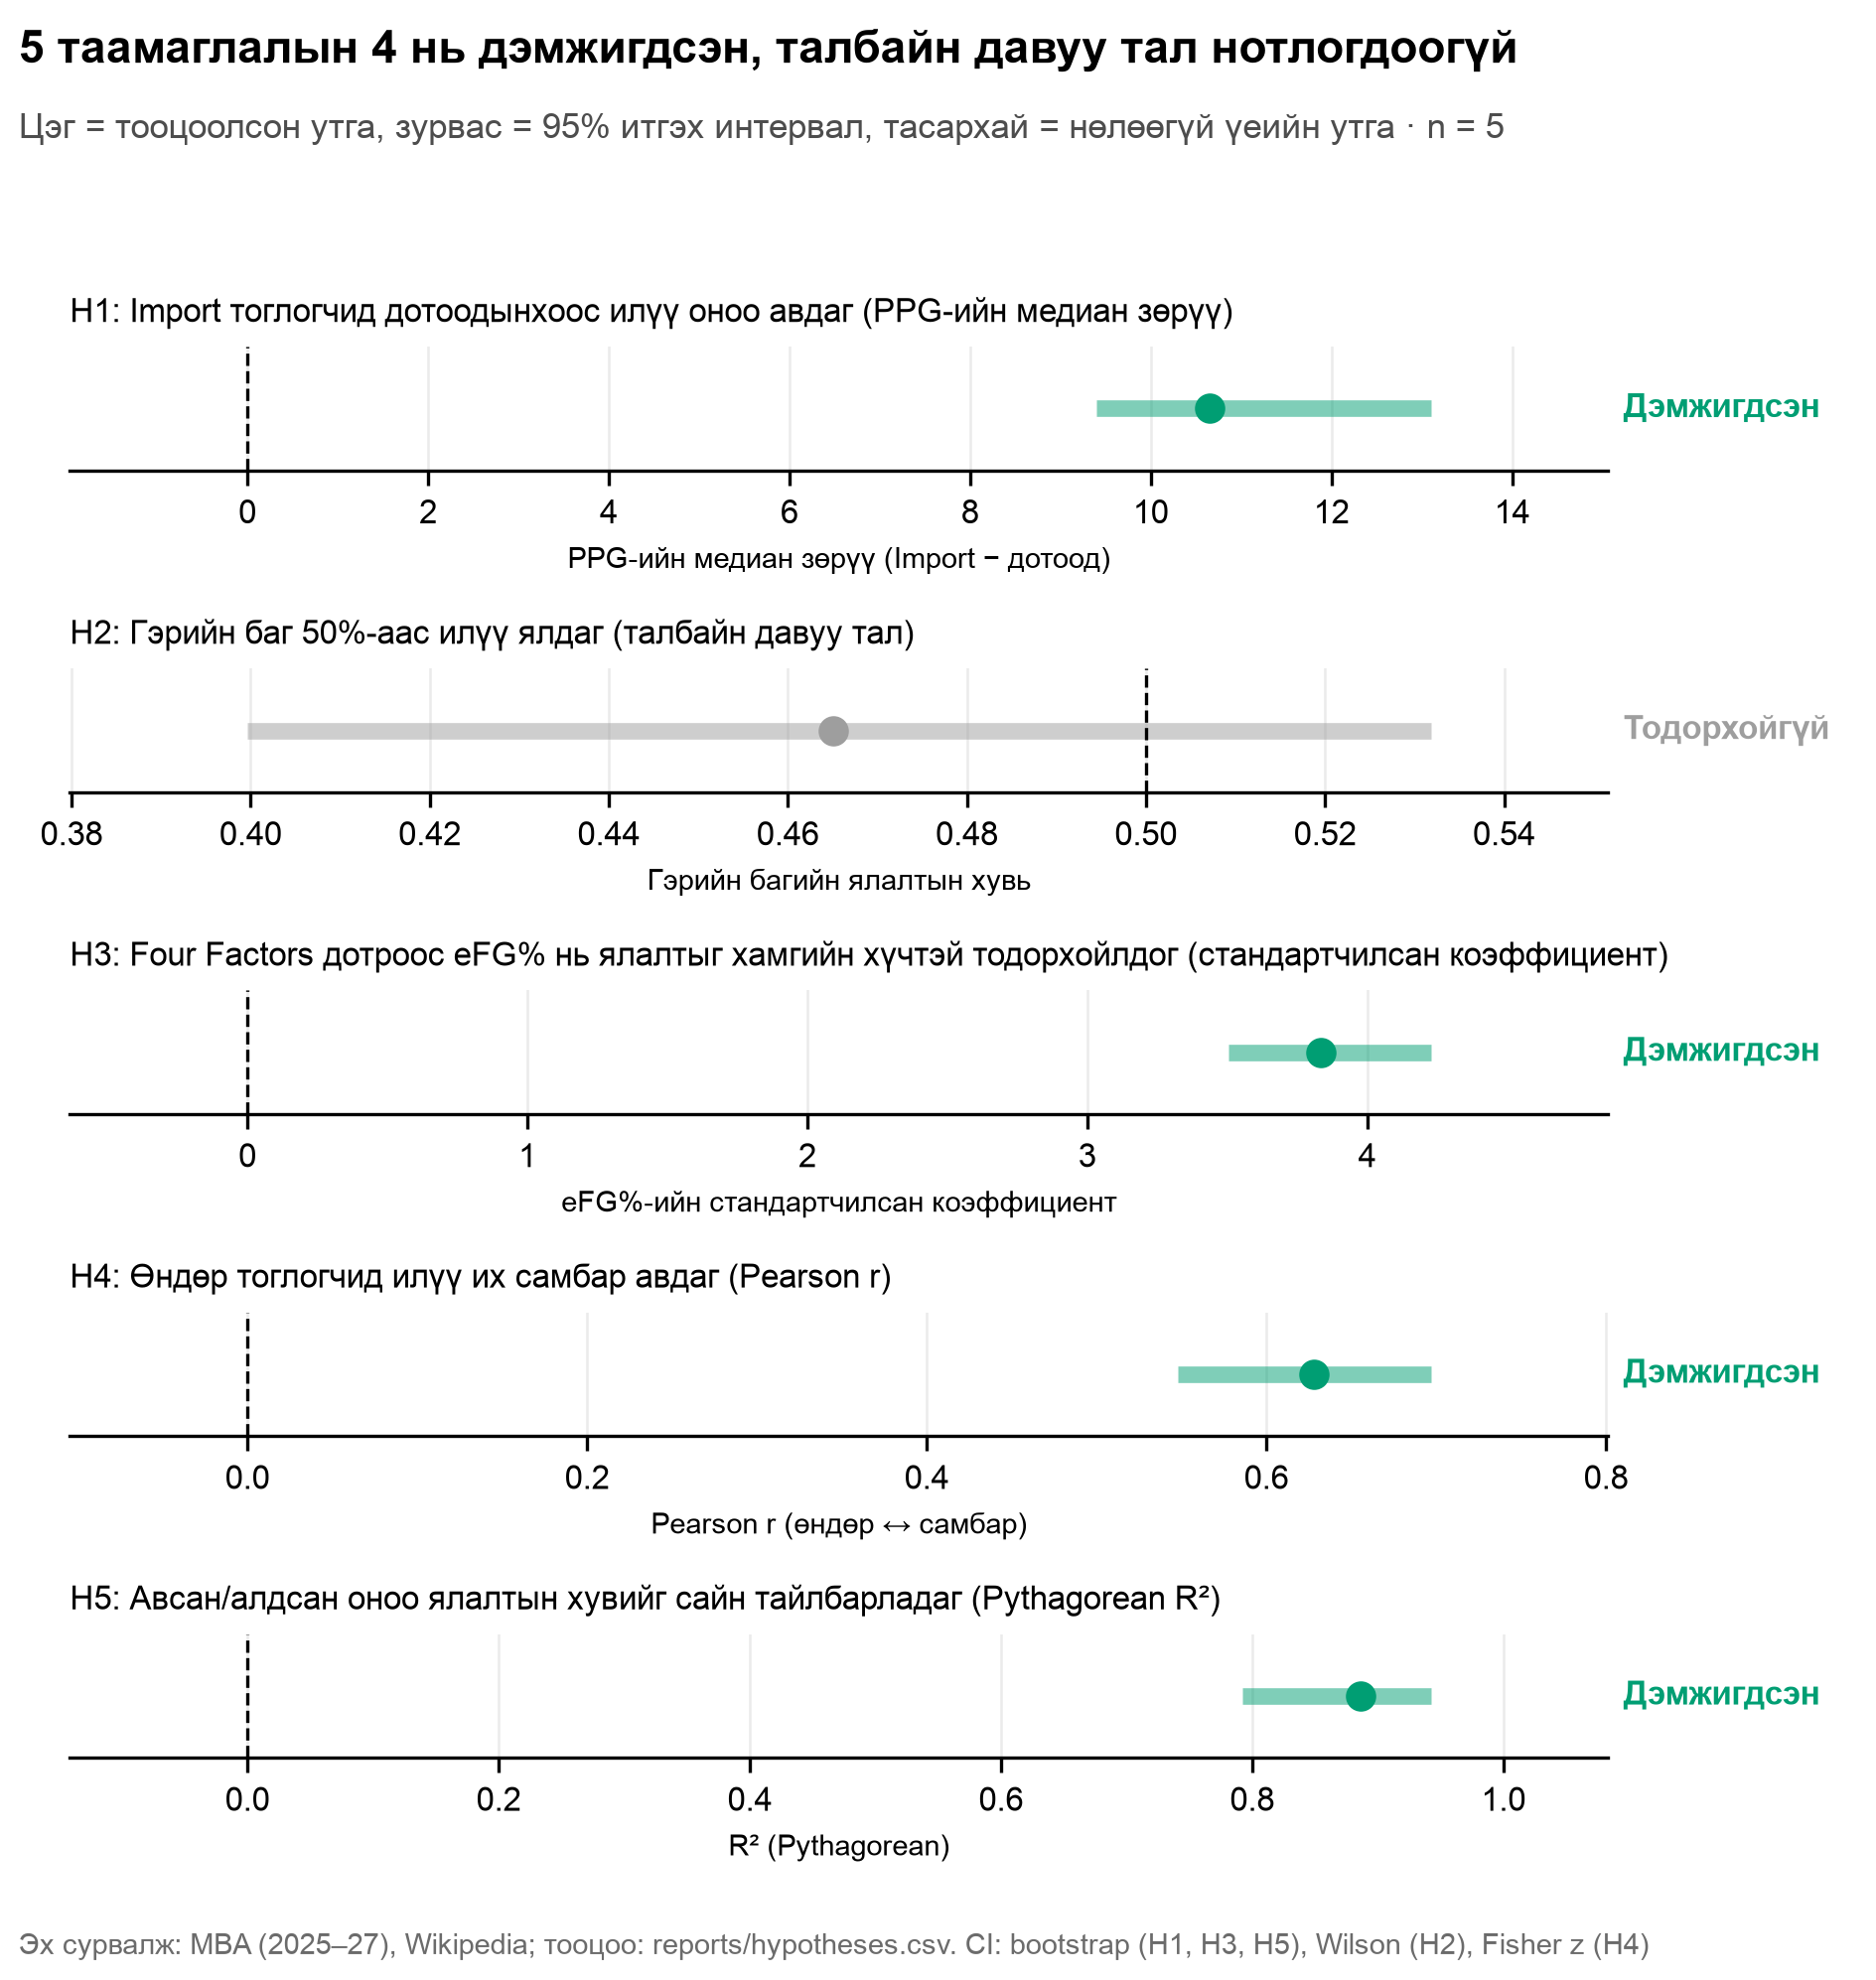

In [3]:
show("U05_hypotheses")

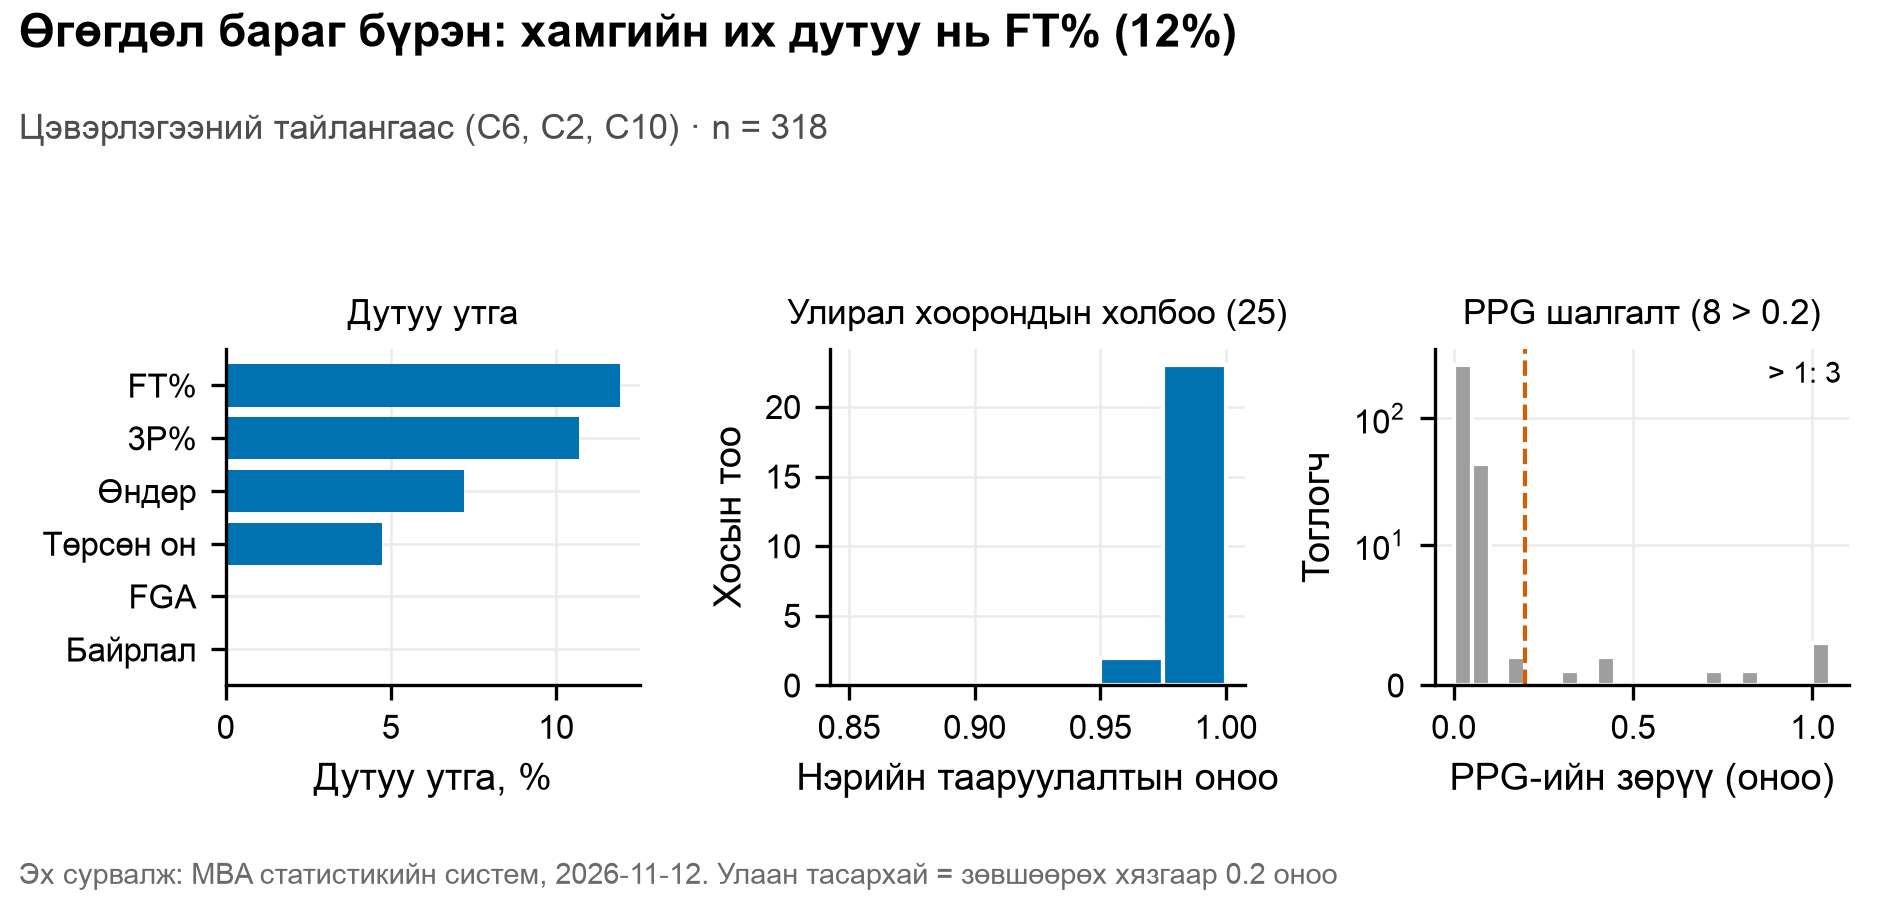

In [4]:
show("U09_data_quality")

In [5]:
from src.charts.summary import verdict
for r in hyp.itertuples():
    print(f"{r.hid}: {verdict(pd.Series(r._asdict()))} — тооцоо {r.estimate:.3f} [{r.ci_lo:.3f}, {r.ci_hi:.3f}]")

H1: Дэмжигдсэн — тооцоо 10.650 [9.400, 13.100]
H2: Тодорхойгүй — тооцоо 0.465 [0.400, 0.532]
H3: Дэмжигдсэн — тооцоо 3.833 [3.506, 4.227]
H4: Дэмжигдсэн — тооцоо 0.628 [0.548, 0.697]
H5: Дэмжигдсэн — тооцоо 0.886 [0.792, 0.942]


## 1. Үндсэн хандлага

**[Ноорог — өөрийн үгээр дахин бичих]** Import тоглогчид тоглогчдын 32% боловч онооны 41%-ийг авдаг; топ ~40% тоглогч онооны 80%-ийг авдаг (P1).

## 2. Хамаарал

**[Ноорог — өөрийн үгээр дахин бичих]** Минут ба оноо хамгийн хүчтэй хамааралтай (r ≈ 0.88); өндөр ↔ самбар r ≈ 0.63 (H4); тоглолтын үр дүнг eFG% хамгийн хүчтэй тайлбарладаг (H3).

## 3. Онцгой утга

In [6]:
ps = pd.read_csv(P / "players_season.csv"); ps = ps[ps.eligible]
g = pd.read_csv(P / "games.csv"); g["margin"] = (g.home_pts - g.away_pts).abs()
q1, q3 = g.margin.quantile([.25, .75]); print("Их зөрүүтэй тоглолт (IQR дүрэм):")
display(g[g.margin > q3 + 1.5 * (q3 - q1)][["date", "home_team", "away_team", "home_pts", "away_pts", "margin"]])

Их зөрүүтэй тоглолт (IQR дүрэм):


,date,home_team,away_team,home_pts,away_pts,margin
116,2026-02-03,Bishrelt Metal,Erdenet Miners,54,86,32
121,2026-02-07,BurenScore Mongolians,Khan Falcons,41,120,79
157,2026-03-18,XAC Broncos,Khan Falcons,93,58,35
200,2026-10-15,Darkhan United,Khan Falcons,102,74,28
223,2026-10-28,Darkhan United,Western Warriors,78,50,28
239,2026-11-06,BCH Knights,SUA TLG Tushig Bagana,87,59,28


**[Ноорог — өөрийн үгээр дахин бичих]** Funnel (U1) дээр хилээс гарсан тоглогчдын ихэнх нь цөөн шидэлттэй — жинхэнэ онцгой ба азын нөлөөг ялгах хэрэгтэй.

## 4. Шалтгаан, үр дагавар

**[Ноорог — өөрийн үгээр дахин бичих]** Хамаарал нь шалтгааныг нотлохгүй: Import тоглогч их минут тоглодог (confounder). Талбайн давуу тал нотлогдоогүй (H2) — ихэнх тоглолт М Банк Аренад болдог.

## 5. Практик санал

**[Ноорог — өөрийн үгээр дахин бичих]** (1) Шидэлтийн сонголтыг сайжруулж eFG%-д анхаарах; (2) дотоодын тоглогчийн минутыг нэмэх хөгжлийн хөтөлбөр; (3) цөөн тоглогчоос хамаарал өндөр багуудад (P2) гүнийг нэмэх; (4) MBA статистикт газар, нэрийн стандарт оруулах.